# Video Game Sales Analysis

## Project Objective

This project explores historical video game sales data to identify trends
across genres, platforms, publishers, regions, and release years.

## Questions

1. How has the number of game releases changed over time?
2. Which genres have the highest total sales?
3. Which platforms have generated the highest sales?
4. Which publishers have generated the highest sales?
5. How do gaming preferences differ between North America, Japan, and PAL regions?
6. Which individual games are the best-selling?
7. Is critic score associated with higher game sales?

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

In [30]:
df = pd.read_csv(r"data\vgchartz-2024.csv")
df.head()

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaN
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaN
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaN
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14


In [4]:
df.shape

(64016, 14)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 64016 entries, 0 to 64015
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   img           64016 non-null  str    
 1   title         64016 non-null  str    
 2   console       64016 non-null  str    
 3   genre         64016 non-null  str    
 4   publisher     64016 non-null  str    
 5   developer     63999 non-null  str    
 6   critic_score  6678 non-null   float64
 7   total_sales   18922 non-null  float64
 8   na_sales      12637 non-null  float64
 9   jp_sales      6726 non-null   float64
 10  pal_sales     12824 non-null  float64
 11  other_sales   15128 non-null  float64
 12  release_date  56965 non-null  str    
 13  last_update   17879 non-null  str    
dtypes: float64(6), str(8)
memory usage: 6.8 MB


In [4]:
df.isna().sum()

img                 0
title               0
console             0
genre               0
publisher           0
developer          17
critic_score    57338
total_sales     45094
na_sales        51379
jp_sales        57290
pal_sales       51192
other_sales     48888
release_date     7051
last_update     46137
dtype: int64

In [5]:
df.duplicated().sum()

np.int64(0)

In [6]:
df.describe()

,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales
count,6678.000000,18922.000000,12637.000000,6726.000000,12824.000000,15128.000000
mean,7.220440,0.349113,0.264740,0.102281,0.149472,0.043041
std,1.457066,0.807462,0.494787,0.168811,0.392653,0.126643
min,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,6.400000,0.030000,0.050000,0.020000,0.010000,0.000000
50%,7.500000,0.120000,0.120000,0.040000,0.040000,0.010000
75%,8.300000,0.340000,0.280000,0.120000,0.140000,0.030000
max,10.000000,20.320000,9.760000,2.130000,9.850000,3.120000


In [7]:
df["genre"].value_counts()

genre
Misc                9304
Action              8557
Adventure           6260
Role-Playing        5721
Sports              5586
Shooter             5410
Platform            4001
Strategy            3685
Puzzle              3521
Racing              3425
Simulation          3158
Fighting            2367
Action-Adventure    1877
Visual Novel         493
Music                297
Party                151
MMO                  115
Education             35
Board Game            33
Sandbox               20
Name: count, dtype: int64

In [8]:
df["console"].value_counts().head(15)

console
PC      12617
PS2      3565
DS       3288
PS4      2878
PS       2707
NS       2337
XBL      2120
PSN      2004
XOne     1963
PS3      1905
PSP      1807
X360     1735
Wii      1676
GBA      1659
GB       1599
Name: count, dtype: int64

In [9]:
df["publisher"].value_counts().head(15)

publisher
Unknown                        8842
Sega                           2207
Ubisoft                        1663
Electronic Arts                1619
Activision                     1582
Konami                         1544
Nintendo                       1476
Sony Computer Entertainment    1372
Microsoft                      1272
THQ                            1111
Capcom                         1092
Atari                           839
EA Sports                       804
Square Enix                     696
Bandai                          574
Name: count, dtype: int64

In [10]:
df["release_date"] = pd.to_datetime(df["release_date"], errors="coerce")
df["last_update"] = pd.to_datetime(df["last_update"], errors="coerce")

In [11]:
df["release_year"] = df["release_date"].dt.year.astype("Int64")

In [12]:
df[["release_date", "release_year"]]

,release_date,release_year
0,2013-09-17,2013
1,2014-11-18,2014
2,2002-10-28,2002
3,2013-09-17,2013
4,2015-11-06,2015
...,...,...
64011,2016-08-11,2016
64012,2020-07-30,2020
64013,2020-07-30,2020
64014,2019-02-28,2019


## Q1: How has the number of game releases changed over time?

In [15]:
releases_by_year = df.groupby("release_year").size()
releases_by_year

release_year
1971       1
1973       1
1975       1
1977      11
1978      45
1979       8
1980      35
1981      50
1982     214
1983     298
1984     102
1985     101
1986     159
1987     270
1988     294
1989     426
1990     657
1991     779
1992     933
1993    1034
1994    1163
1995    1153
1996    1228
1997    1040
1998    1096
1999    1272
2000    1552
2001    1478
2002    1726
2003    1723
2004    1606
2005    1810
2006    2096
2007    2525
2008    2936
2009    4360
2010    3586
2011    3386
2012    1584
2013    1740
2014    2896
2015    1680
2016    1352
2017    1558
2018    1538
2019    1290
2020    1452
2021     422
2022     168
2023     108
2024      22
dtype: int64

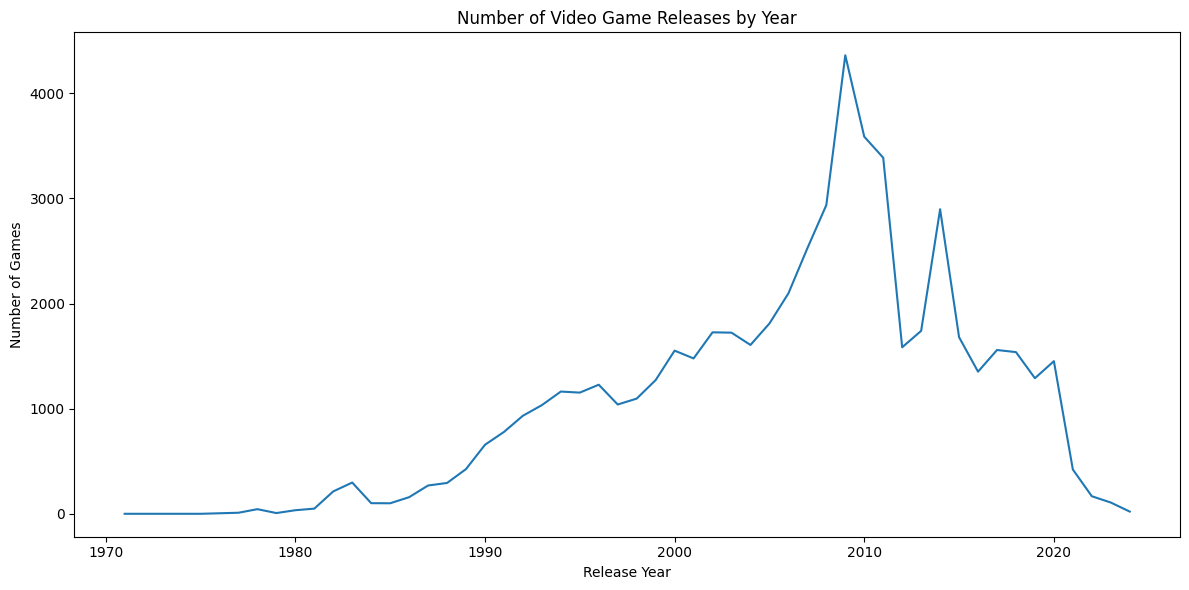

In [16]:
plt.figure(figsize=(12, 6))

plt.plot(releases_by_year.index, releases_by_year.values)

plt.title("Number of Video Game Releases by Year")
plt.xlabel("Release Year")
plt.ylabel("Number of Games")

plt.tight_layout()
plt.show()

In [17]:
releases_by_year.idxmax()

np.int64(2009)

In [18]:
releases_by_year.max()

np.int64(4360)

### Finding

The number of recorded video game releases increased substantially over time,
with the highest number of releases occurring in 2009.

The sharp decline in the most recent years should be interpreted cautiously,
as the dataset may have incomplete coverage for newer releases.

## Q2: Which genres have the highest total sales?

In [41]:
genres_highest_sales = (df.groupby("genre")["total_sales"].sum().sort_values(ascending = False))
genres_highest_sales

genre
Sports              1187.51
Action              1125.89
Shooter              995.50
Misc                 557.79
Racing               525.75
Role-Playing         426.80
Platform             349.15
Fighting             341.13
Adventure            325.39
Simulation           300.65
Action-Adventure     148.52
Puzzle               127.28
Strategy             118.31
Music                 51.75
MMO                    9.31
Party                  6.21
Visual Novel           5.78
Sandbox                1.89
Education              0.97
Board Game             0.33
Name: total_sales, dtype: float64

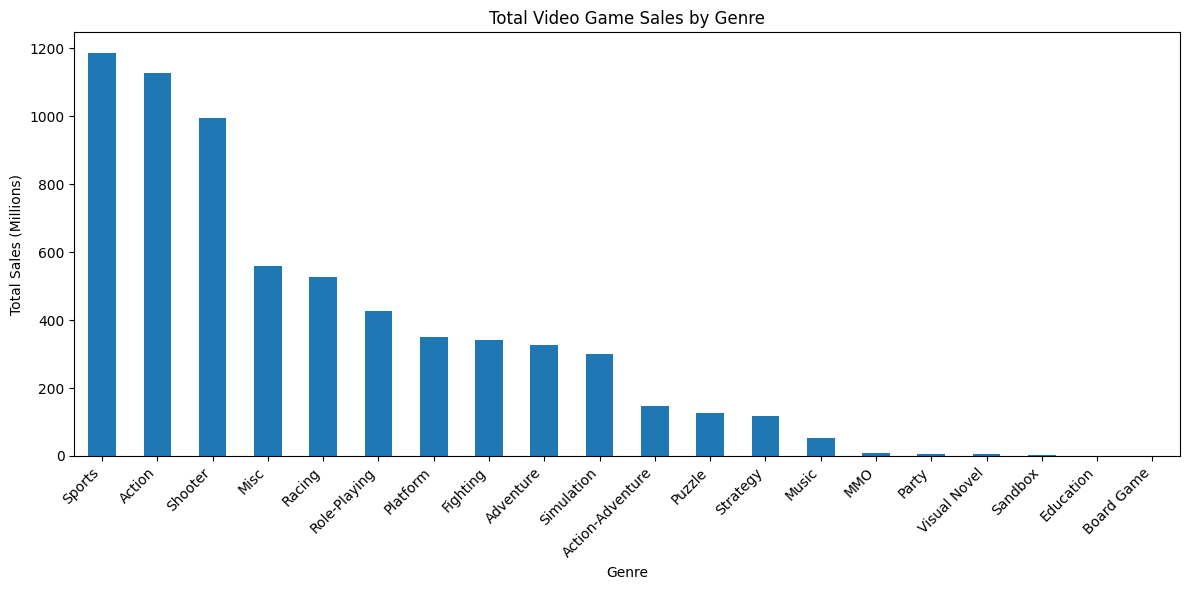

In [42]:
plt.figure(figsize=(12, 6))

genres_highest_sales.plot(kind="bar")

plt.title("Total Video Game Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Total Sales (Millions)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [43]:
genres_highest_sales.idxmax()

'Sports'

In [46]:
genres_highest_sales.head(5)

genre
Sports     1187.51
Action     1125.89
Shooter     995.50
Misc        557.79
Racing      525.75
Name: total_sales, dtype: float64

In [52]:
genres_avg_sales = (df.groupby("genre")["total_sales"].mean().sort_values(ascending = False))
genres_avg_sales.head(5)

genre
Sandbox             1.890000
Shooter             0.670370
Action-Adventure    0.562576
Sports              0.457262
Action              0.396580
Name: total_sales, dtype: float64

In [54]:
sales_count_by_genre = (df.groupby("genre")["total_sales"].count().sort_values(ascending=False))
sales_count_by_genre

genre
Action              2839
Sports              2597
Misc                2004
Adventure           1893
Role-Playing        1491
Shooter             1485
Racing              1431
Simulation          1121
Platform             951
Fighting             871
Strategy             820
Puzzle               723
Action-Adventure     264
Visual Novel         218
Music                147
MMO                   30
Party                 29
Education              4
Board Game             3
Sandbox                1
Name: total_sales, dtype: int64

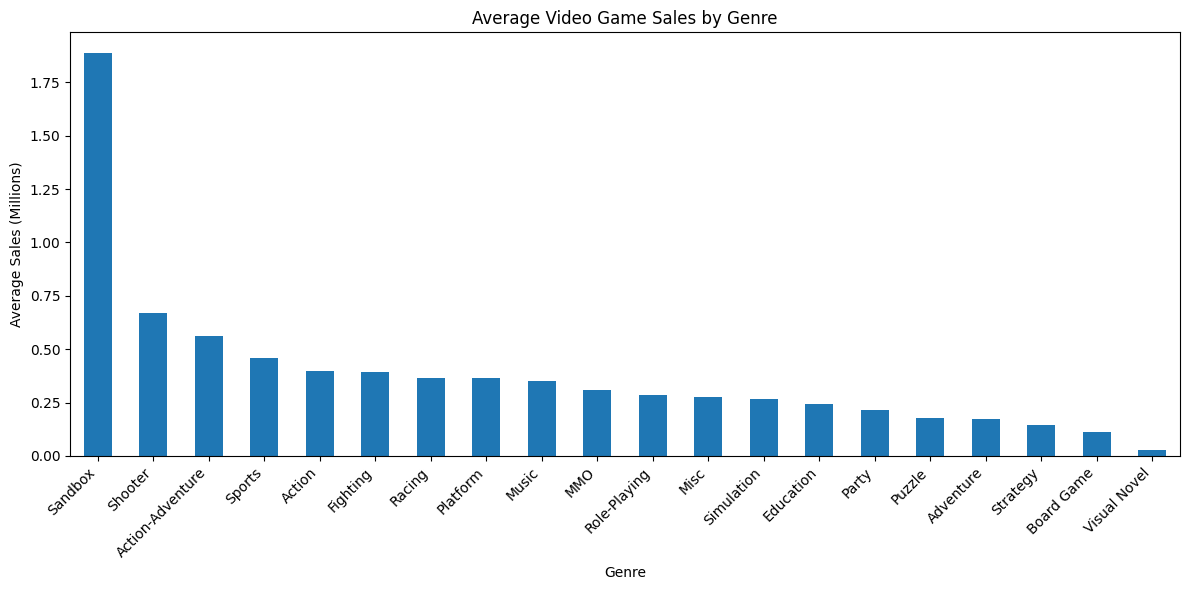

In [55]:
plt.figure(figsize=(12, 6))

genres_avg_sales.plot(kind="bar")

plt.title("Average Video Game Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Sales (Millions)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [56]:
genre_sales_summary = (df.groupby("genre")["total_sales"].agg(["count", "sum", "mean"]).sort_values("mean", ascending=False))
genre_sales_summary

,count,sum,mean
genre,,,
Sandbox,1,1.89,1.890000
Shooter,1485,995.50,0.670370
Action-Adventure,264,148.52,0.562576
Sports,2597,1187.51,0.457262
Action,2839,1125.89,0.396580
Fighting,871,341.13,0.391653
Racing,1431,525.75,0.367400
Platform,951,349.15,0.367140
Music,147,51.75,0.352041


In [57]:
reliable_genres = genre_sales_summary[genre_sales_summary["count"] >= 100].sort_values("mean", ascending=False)
reliable_genres

,count,sum,mean
genre,,,
Shooter,1485,995.50,0.670370
Action-Adventure,264,148.52,0.562576
Sports,2597,1187.51,0.457262
Action,2839,1125.89,0.396580
Fighting,871,341.13,0.391653
Racing,1431,525.75,0.367400
Platform,951,349.15,0.367140
Music,147,51.75,0.352041
Role-Playing,1491,426.80,0.286251


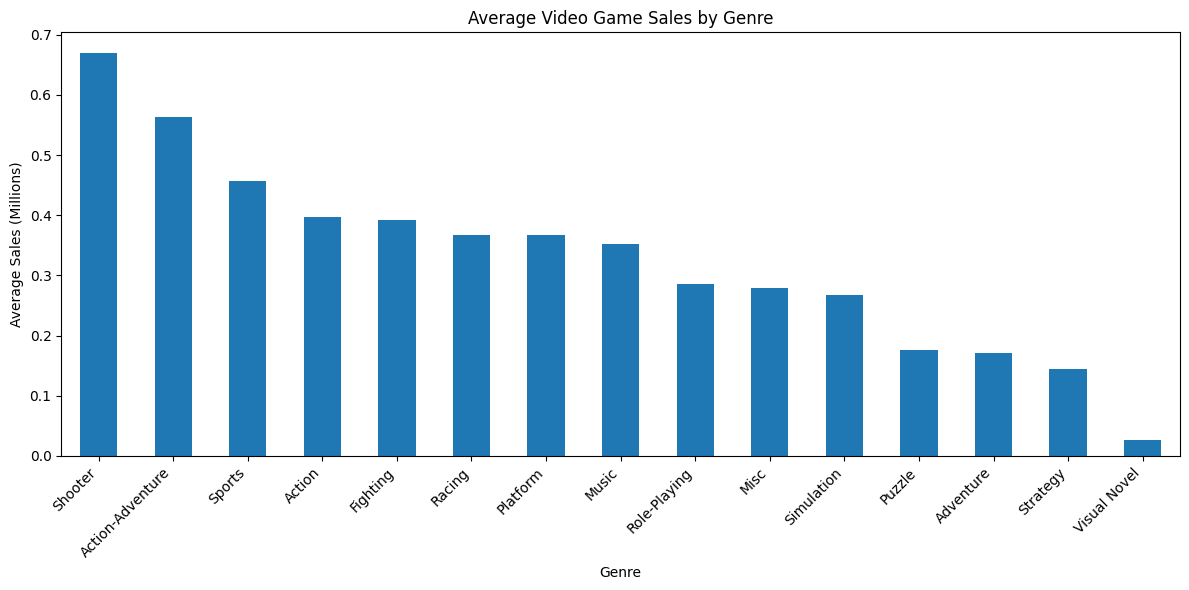

In [58]:
plt.figure(figsize=(12, 6))

reliable_genres["mean"].plot(kind="bar")

plt.title("Average Video Game Sales by Genre")
plt.xlabel("Genre")
plt.ylabel("Average Sales (Millions)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Finding

Sports generated the highest total recorded sales, followed by Action and Shooter.

However, total sales alone can be influenced by the number of games released in each
genre. When comparing average sales per title, Shooter ranks highest among genres
with at least 100 games containing sales data.

Sandbox shows the highest raw average, but only one Sandbox title has recorded
sales data, making this result unsuitable for a meaningful genre comparison.

Because many games in the dataset have missing sales values, these results represent
only titles for which sales data is available.

## Q3: Which platforms have generated the highest sales?

In [23]:
platforms_highest_sales = df.groupby("console")["total_sales"].sum().sort_values(ascending=False)
platforms_highest_sales.head(10)

console
PS2     1027.76
X360     859.79
PS3      839.70
PS       546.25
PS4      539.92
Wii      459.44
DS       458.17
XOne     268.96
PSP      245.29
XB       232.05
Name: total_sales, dtype: float64

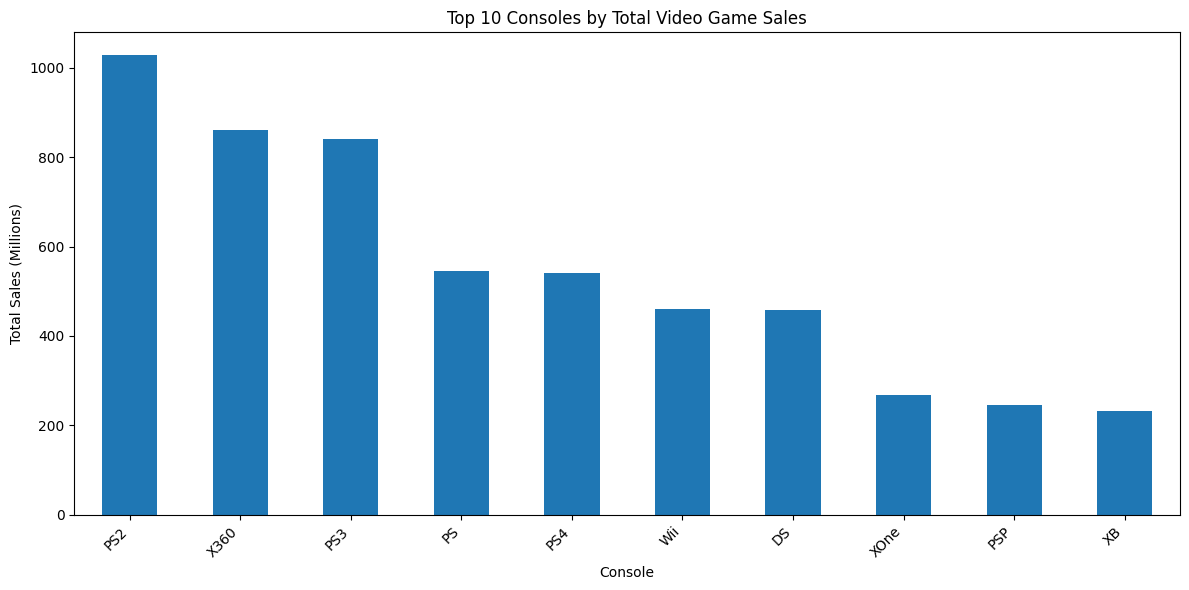

In [24]:
top_10_platforms = platforms_highest_sales.head(10)

plt.figure(figsize=(12, 6))
top_10_platforms.plot(kind="bar")

plt.title("Top 10 Consoles by Total Video Game Sales")
plt.xlabel("Console")
plt.ylabel("Total Sales (Millions)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [25]:
platform_sales_summary = (df.groupby("console")["total_sales"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False))
platform_sales_summary.head(10)

,count,sum,mean
console,,,
PS2,2126,1027.76,0.483424
X360,1302,859.79,0.660361
PS3,1348,839.70,0.622923
PS,1130,546.25,0.483407
PS4,908,539.92,0.594626
Wii,1357,459.44,0.338570
DS,2396,458.17,0.191223
XOne,524,268.96,0.513282
PSP,1340,245.29,0.183052


In [26]:
platform_sales_summary.sort_values("mean", ascending=False).head(10)

,count,sum,mean
console,,,
GBC,3,4.34,1.446667
NES,48,47.93,0.998542
GEN,27,18.83,0.697407
X360,1302,859.79,0.660361
PS3,1348,839.70,0.622923
2600,126,75.66,0.600476
PS4,908,539.92,0.594626
XOne,524,268.96,0.513282
PS2,2126,1027.76,0.483424


In [27]:
reliable_platforms = (platform_sales_summary[platform_sales_summary["count"] >= 100].sort_values("mean", ascending=False))
reliable_platforms.head(10)

,count,sum,mean
console,,,
X360,1302,859.79,0.660361
PS3,1348,839.70,0.622923
2600,126,75.66,0.600476
PS4,908,539.92,0.594626
XOne,524,268.96,0.513282
PS2,2126,1027.76,0.483424
PS,1130,546.25,0.483407
Wii,1357,459.44,0.338570
N64,279,93.79,0.336165


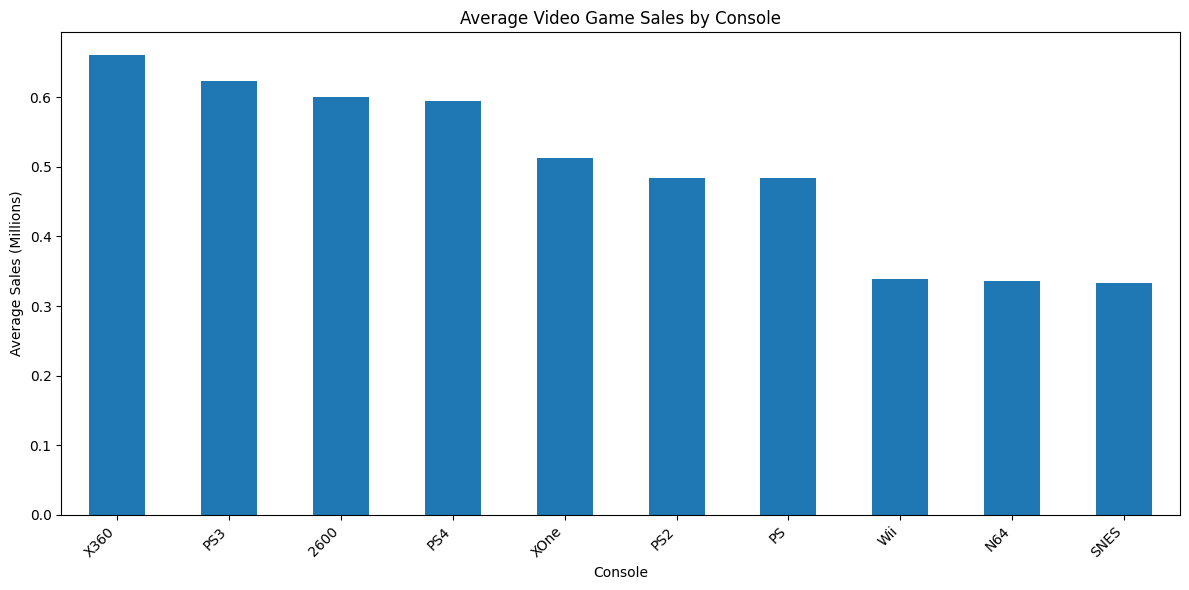

In [28]:
plt.figure(figsize=(12, 6))

reliable_platforms["mean"].head(10).plot(kind="bar")

plt.title("Average Video Game Sales by Console")
plt.xlabel("Console")
plt.ylabel("Average Sales (Millions)")

plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

### Finding

PS2 has the highest total recorded sales in the dataset, with approximately
1.03 billion units, followed by Xbox 360 and PS3.

However, total sales are influenced by the number of games available on each
platform. Among platforms with at least 100 games containing recorded sales,
Xbox 360 has the highest average sales per title, followed by PS3.

Platforms with very small sample sizes were excluded from the average-sales
comparison to avoid misleading results.

## Q4: Which publishers have generated the highest sales?

In [29]:
publisher_highest_sales = (df.groupby("publisher")["total_sales"].sum().sort_values(ascending=False))
publisher_highest_sales.head(10)

publisher
Activision                     722.77
Electronic Arts                644.13
EA Sports                      485.66
Ubisoft                        462.57
THQ                            320.89
Sony Computer Entertainment    311.08
Rockstar Games                 239.67
Konami                         210.70
Sega                           206.38
Nintendo                       140.80
Name: total_sales, dtype: float64

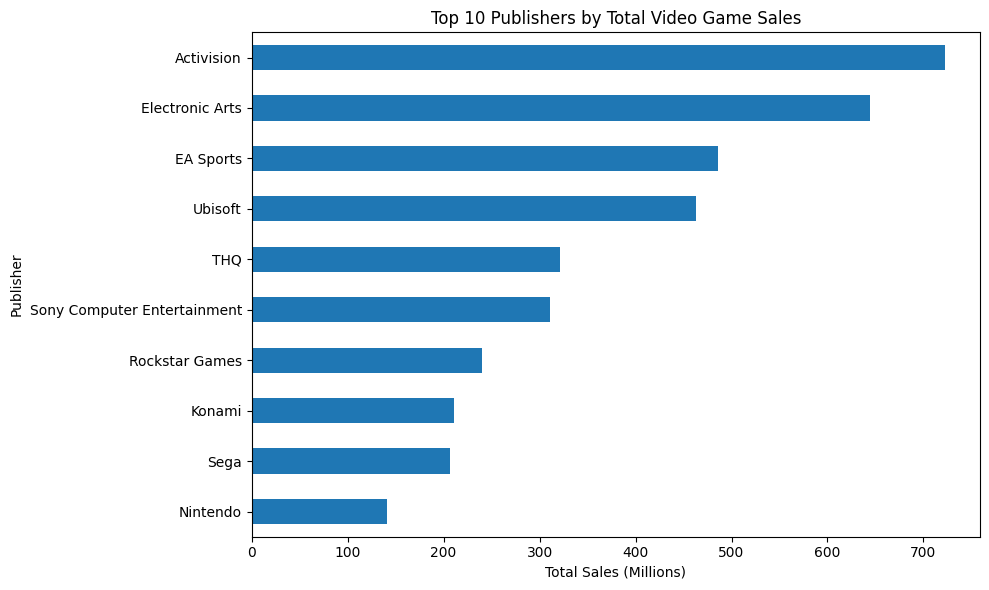

In [30]:
top_10_publishers = publisher_highest_sales.head(10)

plt.figure(figsize=(10, 6))

top_10_publishers.sort_values().plot(kind="barh")

plt.title("Top 10 Publishers by Total Video Game Sales")
plt.xlabel("Total Sales (Millions)")
plt.ylabel("Publisher")

plt.tight_layout()
plt.show()

In [31]:
publisher_sales_summary = (df.groupby("publisher")["total_sales"].agg(["count", "sum", "mean"]).sort_values("sum", ascending=False))
publisher_sales_summary.head(10)

,count,sum,mean
publisher,,,
Activision,1044,722.77,0.692308
Electronic Arts,843,644.13,0.764093
EA Sports,540,485.66,0.899370
Ubisoft,1012,462.57,0.457085
THQ,726,320.89,0.441997
Sony Computer Entertainment,568,311.08,0.547676
Rockstar Games,93,239.67,2.577097
Konami,769,210.70,0.273992
Sega,641,206.38,0.321966


In [32]:
reliable_publishers = (publisher_sales_summary[publisher_sales_summary["count"] >= 50].sort_values("mean", ascending=False))
reliable_publishers.head(10)

,count,sum,mean
publisher,,,
Rockstar Games,93,239.67,2.577097
Bethesda Softworks,113,111.08,0.983009
EA Sports,540,485.66,0.899370
LucasArts,138,118.48,0.858551
Electronic Arts,843,644.13,0.764093
Activision,1044,722.77,0.692308
Microsoft Game Studios,92,58.64,0.637391
Warner Bros. Interactive Entertainment,166,103.51,0.623554
Warner Bros. Interactive,126,78.07,0.619603


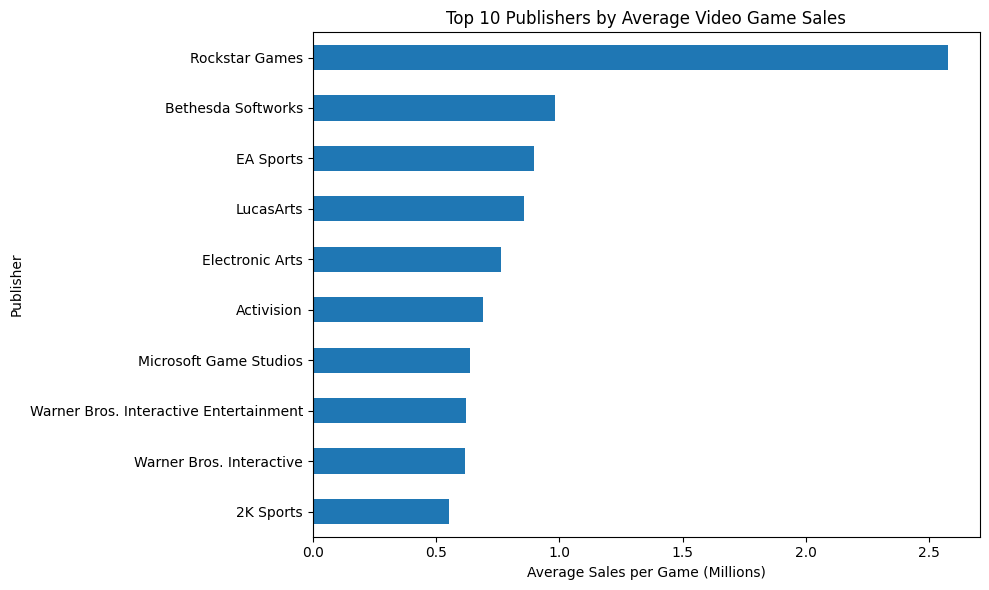

In [34]:
top_10_avg_publishers = reliable_publishers.head(10)

plt.figure(figsize=(10, 6))

top_10_avg_publishers["mean"].sort_values().plot(kind="barh")

plt.title("Top 10 Publishers by Average Video Game Sales")
plt.xlabel("Average Sales per Game (Millions)")
plt.ylabel("Publisher")

plt.tight_layout()
plt.show()

### Finding

Activision has the highest total recorded sales, followed by Electronic Arts
and EA Sports.

However, among publishers with at least 50 games containing recorded sales,
Rockstar Games has the highest average sales per title at approximately
2.58 million units per game.

This suggests that publishers with the largest overall sales are not
necessarily those with the highest sales per individual title. Publisher
naming variations may also affect the results, as related companies or labels
can appear under separate names.

## Q5: How do gaming preferences differ between North America, Japan, and PAL regions?

In [37]:
regional_sales = df[["na_sales", "jp_sales", "pal_sales", "other_sales"]].sum().sort_values(ascending = False)
regional_sales

na_sales       3345.52
pal_sales      1916.83
jp_sales        687.94
other_sales     651.12
dtype: float64

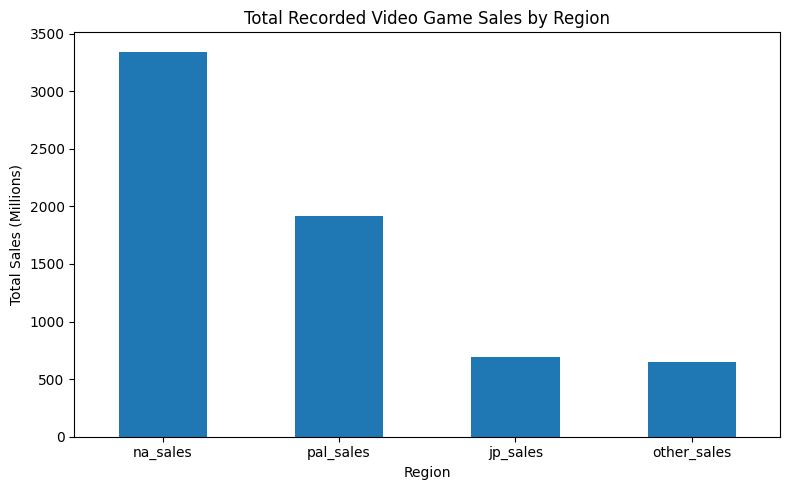

In [38]:
plt.figure(figsize=(8, 5))

regional_sales.plot(kind="bar")

plt.title("Total Recorded Video Game Sales by Region")
plt.xlabel("Region")
plt.ylabel("Total Sales (Millions)")

plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

In [39]:
genre_regional_sales = (df.groupby("genre")[["na_sales", "jp_sales", "pal_sales", "other_sales"]].sum())
genre_regional_sales

,na_sales,jp_sales,pal_sales,other_sales
genre,,,,
Action,589.69,80.30,342.52,112.41
Action-Adventure,65.09,5.46,59.52,18.40
Adventure,157.26,46.11,91.52,30.11
Board Game,0.06,0.04,0.22,0.02
Education,0.68,0.00,0.20,0.08
Fighting,173.96,58.61,79.84,28.65
MMO,3.95,1.39,2.94,1.03
Misc,295.66,56.24,146.71,58.52
Music,25.97,5.84,15.02,4.93


In [40]:
genre_regional_sales["na_sales"].sort_values(ascending=False).head(5)

genre
Sports     607.47
Action     589.69
Shooter    528.27
Misc       295.66
Racing     269.72
Name: na_sales, dtype: float64

In [41]:
genre_regional_sales["jp_sales"].sort_values(ascending=False).head(5)

genre
Role-Playing    130.56
Sports          109.27
Action           80.30
Fighting         58.61
Misc             56.24
Name: jp_sales, dtype: float64

In [42]:
genre_regional_sales["pal_sales"].sort_values(ascending=False).head(5)

genre
Action     342.52
Sports     341.92
Shooter    324.74
Racing     179.14
Misc       146.71
Name: pal_sales, dtype: float64

In [43]:
genre_regional_sales["other_sales"].sort_values(ascending=False).head(5)

genre
Sports     128.19
Action     112.41
Shooter    108.43
Misc        58.52
Racing      56.44
Name: other_sales, dtype: float64

In [44]:
genre_regional_share = (genre_regional_sales.div(genre_regional_sales.sum(axis=0), axis=1)* 100)
genre_regional_share

,na_sales,jp_sales,pal_sales,other_sales
genre,,,,
Action,17.626258,11.672530,17.869086,17.264099
Action-Adventure,1.945587,0.793674,3.105127,2.825900
Adventure,4.700615,6.702619,4.774550,4.624340
Board Game,0.001793,0.005814,0.011477,0.003072
Education,0.020326,0.000000,0.010434,0.012287
Fighting,5.199790,8.519638,4.165210,4.400111
MMO,0.118068,0.202053,0.153378,0.158189
Misc,8.837490,8.175132,7.653783,8.987591
Music,0.776262,0.848911,0.783585,0.757157


In [45]:
genre_regional_share["na_sales"].sort_values(ascending=False).head(5)

genre
Sports     18.157715
Action     17.626258
Shooter    15.790370
Misc        8.837490
Racing      8.062125
Name: na_sales, dtype: float64

In [46]:
genre_regional_share["jp_sales"].sort_values(ascending=False).head(5)

genre
Role-Playing    18.978399
Sports          15.883653
Action          11.672530
Fighting         8.519638
Misc             8.175132
Name: jp_sales, dtype: float64

In [47]:
genre_regional_share["pal_sales"].sort_values(ascending=False).head(5)

genre
Action     17.869086
Sports     17.837784
Shooter    16.941513
Racing      9.345638
Misc        7.653783
Name: pal_sales, dtype: float64

In [48]:
selected_genres = [
    "Sports",
    "Action",
    "Shooter",
    "Role-Playing",
    "Racing"
]

regional_comparison = genre_regional_share.loc[selected_genres,["na_sales", "jp_sales", "pal_sales"]]
regional_comparison

,na_sales,jp_sales,pal_sales
genre,,,
Sports,18.157715,15.883653,17.837784
Action,17.626258,11.672530,17.869086
Shooter,15.790370,4.940838,16.941513
Role-Playing,5.131340,18.978399,4.748465
Racing,8.062125,2.940663,9.345638


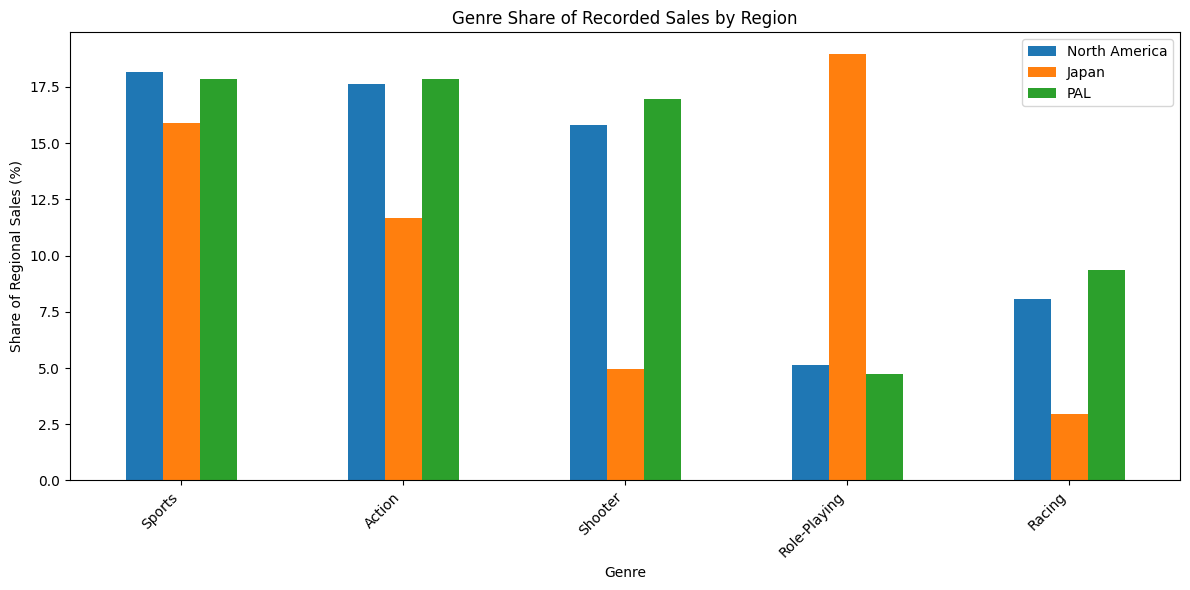

In [49]:
regional_comparison.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Genre Share of Recorded Sales by Region")
plt.xlabel("Genre")
plt.ylabel("Share of Regional Sales (%)")

plt.xticks(rotation=45, ha="right")
plt.legend(["North America", "Japan", "PAL"])

plt.tight_layout()
plt.show()

### Finding

North America and the PAL region show similar genre preferences, with Sports,
Action, and Shooter accounting for the largest shares of recorded sales.

Japan shows a noticeably different pattern. Role-Playing games account for
approximately 19% of recorded Japanese sales, compared with only around 5%
in North America and the PAL region.

Shooter games show the opposite pattern, representing approximately 16–17%
of recorded sales in North America and PAL, but only about 5% in Japan.

These results indicate substantial regional differences in genre preferences.

## Q6: Which individual games are the best-selling?

In [13]:
df

,img,title,console,genre,publisher,developer,critic_score,total_sales,na_sales,jp_sales,pal_sales,other_sales,release_date,last_update,release_year
0,/games/boxart/full_6510540AmericaFrontccc.jpg,Grand Theft Auto V,PS3,Action,Rockstar Games,Rockstar North,9.4,20.32,6.37,0.99,9.85,3.12,2013-09-17,NaT,2013
1,/games/boxart/full_5563178AmericaFrontccc.jpg,Grand Theft Auto V,PS4,Action,Rockstar Games,Rockstar North,9.7,19.39,6.06,0.60,9.71,3.02,2014-11-18,2018-01-03,2014
2,/games/boxart/827563ccc.jpg,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,Rockstar North,9.6,16.15,8.41,0.47,5.49,1.78,2002-10-28,NaT,2002
3,/games/boxart/full_9218923AmericaFrontccc.jpg,Grand Theft Auto V,X360,Action,Rockstar Games,Rockstar North,NaN,15.86,9.06,0.06,5.33,1.42,2013-09-17,NaT,2013
4,/games/boxart/full_4990510AmericaFrontccc.jpg,Call of Duty: Black Ops 3,PS4,Shooter,Activision,Treyarch,8.1,15.09,6.18,0.41,6.05,2.44,2015-11-06,2018-01-14,2015
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64011,/games/boxart/full_2779838AmericaFrontccc.jpg,XBlaze Lost: Memories,PC,Visual Novel,Aksys Games,Arc System Works,NaN,NaN,NaN,NaN,NaN,NaN,2016-08-11,2019-01-28,2016
64012,/games/boxart/full_8031506AmericaFrontccc.jpg,"Yoru, Tomosu",PS4,Visual Novel,Nippon Ichi Software,Nippon Ichi Software,NaN,NaN,NaN,NaN,NaN,NaN,2020-07-30,2020-05-09,2020
64013,/games/boxart/full_6553045AmericaFrontccc.jpg,"Yoru, Tomosu",NS,Visual Novel,Nippon Ichi Software,Nippon Ichi Software,NaN,NaN,NaN,NaN,NaN,NaN,2020-07-30,2020-05-09,2020
64014,/games/boxart/full_6012940JapanFrontccc.png,Yunohana SpRING! ~Mellow Times~,NS,Visual Novel,Idea Factory,Otomate,NaN,NaN,NaN,NaN,NaN,NaN,2019-02-28,2019-02-24,2019


In [20]:
top_game_platform_releases = df[['title', 'console', 'genre', 'publisher', 'total_sales']].sort_values('total_sales', ascending=False).head(15)
top_game_platform_releases

,title,console,genre,publisher,total_sales
0,Grand Theft Auto V,PS3,Action,Rockstar Games,20.32
1,Grand Theft Auto V,PS4,Action,Rockstar Games,19.39
2,Grand Theft Auto: Vice City,PS2,Action,Rockstar Games,16.15
3,Grand Theft Auto V,X360,Action,Rockstar Games,15.86
4,Call of Duty: Black Ops 3,PS4,Shooter,Activision,15.09
5,Call of Duty: Modern Warfare 3,X360,Shooter,Activision,14.82
6,Call of Duty: Black Ops,X360,Shooter,Activision,14.74
7,Red Dead Redemption 2,PS4,Action-Adventure,Rockstar Games,13.94
8,Call of Duty: Black Ops II,X360,Shooter,Activision,13.86
9,Call of Duty: Black Ops II,PS3,Shooter,Activision,13.80


In [21]:
top_games_overall = (df.groupby("title")["total_sales"].sum().sort_values(ascending=False).head(15))
top_games_overall

title
Grand Theft Auto V                64.29
Call of Duty: Black Ops           30.99
Call of Duty: Modern Warfare 3    30.71
Call of Duty: Black Ops II        29.59
Call of Duty: Ghosts              28.80
Call of Duty: Black Ops 3         26.72
Call of Duty: Modern Warfare 2    25.02
Minecraft                         24.01
Grand Theft Auto IV               22.53
Call of Duty: Advanced Warfare    21.78
The Elder Scrolls V: Skyrim       20.51
Call of Duty: WWII                19.82
Red Dead Redemption 2             19.71
Call of Duty 4: Modern Warfare    18.33
FIFA 15                           18.03
Name: total_sales, dtype: float64

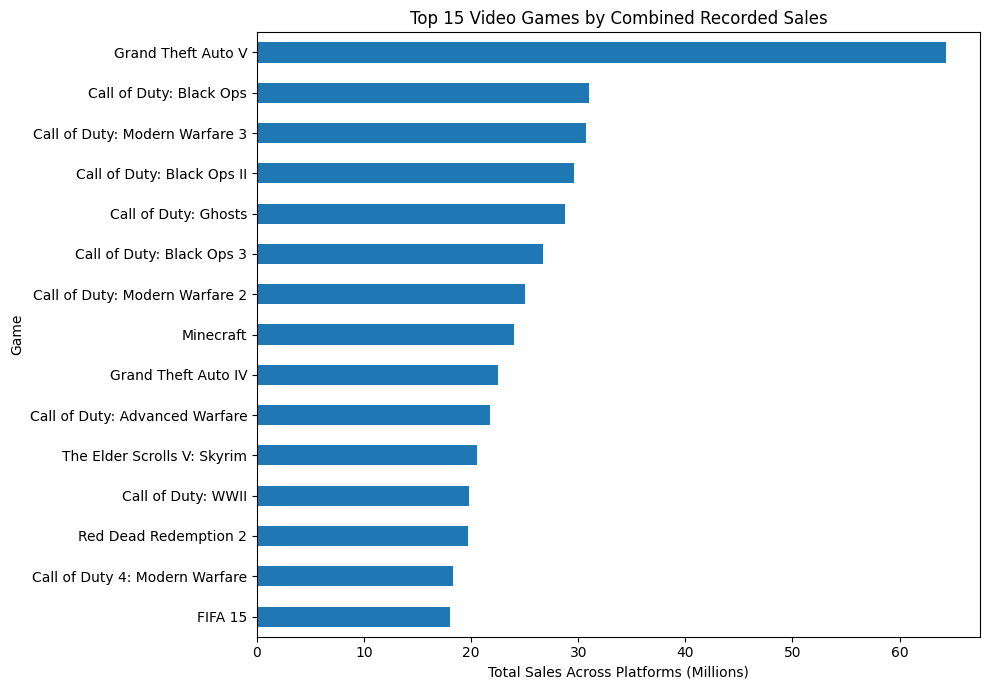

In [22]:
plt.figure(figsize=(10, 7))

top_games_overall.sort_values().plot(kind="barh")

plt.title("Top 15 Video Games by Combined Recorded Sales")
plt.xlabel("Total Sales Across Platforms (Millions)")
plt.ylabel("Game")

plt.tight_layout()
plt.show()

### Finding

The best-selling titles were identified by combining recorded sales across all
platform versions of the same game. This differs from ranking individual game releases, where the same title may
appear multiple times for different consoles.

## Q7: Is critic score associated with higher game sales?

In [24]:
critic_sales = df[["critic_score", "total_sales"]].dropna()
critic_sales

,critic_score,total_sales
0,9.4,20.32
1,9.7,19.39
2,9.6,16.15
4,8.1,15.09
5,8.7,14.82
...,...,...
18895,7.3,0.00
18907,7.8,0.00
18917,7.0,0.00
18918,6.4,0.00


In [26]:
critic_sales.corr()

,critic_score,total_sales
critic_score,1.000000,0.281166
total_sales,0.281166,1.000000


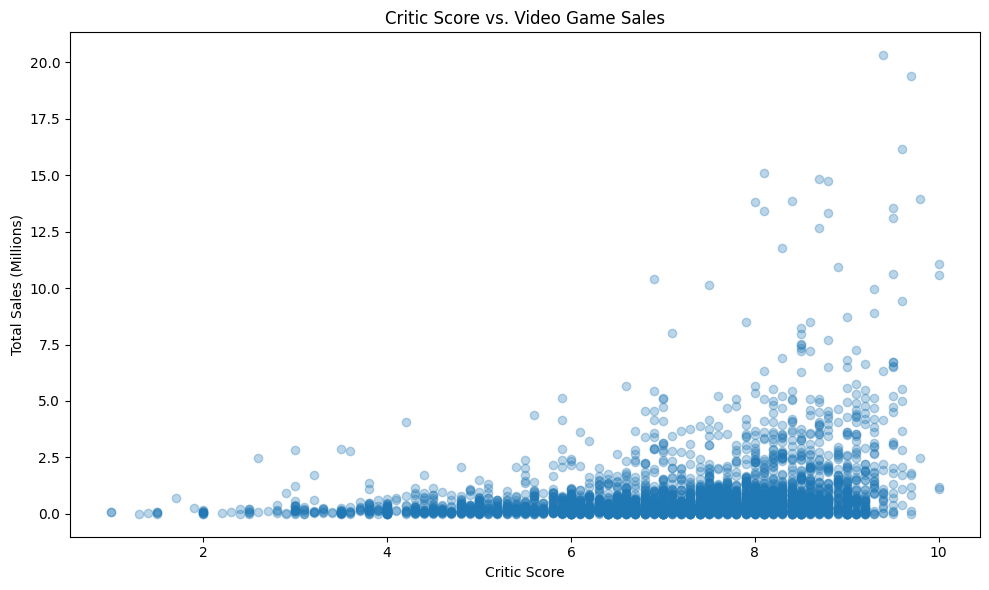

In [27]:
plt.figure(figsize=(10, 6))

plt.scatter(
    critic_sales["critic_score"],
    critic_sales["total_sales"],
    alpha=0.3
)

plt.title("Critic Score vs. Video Game Sales")
plt.xlabel("Critic Score")
plt.ylabel("Total Sales (Millions)")

plt.tight_layout()
plt.show()

### Finding

Among the 4,126 game records containing both critic scores and recorded sales,
critic score and total sales have a positive correlation of approximately 0.28.

This indicates a weak positive relationship: games with higher critic scores
tend to have somewhat higher sales, but critic scores alone do not strongly
predict commercial performance.

The relationship should not be interpreted as causal. Factors such as
franchise popularity, marketing, platform availability, release timing, and
other variables not analyzed here may also influence sales.

## Conclusion

The analysis revealed several notable patterns in the available video game
sales data:

- Recorded game releases peaked in 2009 with 4,360 titles.
- Sports generated the highest total recorded genre sales, while Shooter had
  the highest average sales per title among genres with sufficient sales data.
- PS2 generated the highest total recorded platform sales, while Xbox 360 had
  the highest average sales among platforms with at least 100 recorded titles.
- Activision led publishers in total recorded sales, while Rockstar Games had
  the highest average sales per title among publishers with at least 50 games
  containing sales data.
- North American and PAL genre preferences were similar, while Japan showed
  a much stronger preference for Role-Playing games and a much smaller share
  of Shooter sales.
- Grand Theft Auto V had the highest combined recorded sales across platforms.
- Critic scores showed a weak positive correlation with total sales
  (r ≈ 0.28), suggesting that critical reception alone does not strongly
  explain commercial performance.

### Limitations

A substantial portion of the dataset contains missing sales and critic-score
values. Recent release years may also be incomplete, and publisher naming
variations may split related companies or labels across multiple categories.
Results should therefore be interpreted as patterns within the recorded data
rather than complete measurements of the entire video game market.